### Project: NovaPay Fraud Detection ML Solution

Task Description:

I am working to design and implement an end-to-end supervised machine learning fraud detection solution for NovaPay using Python. The goal is to replace the current static rules-based approach with a data-driven model that can identify fraudulent transactions in real time, while keeping false alarms (false positives) low enough to protect customer experience.

Specifically, I am expected to:

* Ingest and profile transaction data to understand fraud prevalence, data quality issues, and key patterns.

* Prepare and transform the data (cleaning, encoding categorical fields, scaling numerical fields, handling missing values) and engineer fraud-relevant features such as velocity metrics, device/account mismatch indicators, and temporal behavior patterns.

* Address severe class imbalance (fraud <1%) using appropriate strategies such as class weighting and/or carefully chosen resampling techniques.

* Train and compare supervised classifiers including Logistic Regression and advanced tree-based models such as XGBoost (and optionally Random Forest/LightGBM), tuning hyperparameters and evaluating using fraud-appropriate metrics (Recall, Precision, F1, PR-AUC/ROC-AUC).

* Select a final model and threshold strategy that achieves improved fraud recall (target: ≥15% recall improvement over baseline) while maintaining acceptable precision to reduce customer friction.

* Explain model predictions using SHAP, producing transaction-level explanations suitable for fraud analysts and regulatory stakeholders.

* Deploy the model as a FastAPI microservice exposing a /score endpoint for real-time scoring, and package it using Docker for portability.

* Propose monitoring and retraining using drift detection (e.g., Evidently) and a retraining schedule to ensure the system remains effective as fraud patterns evolve.

Submission Text: 

This project presents the design and implementation of a supervised machine learning–based fraud detection system for NovaPay, a digital money transfer platform operating at scale. The objective was to replace a static, rules-based fraud framework with a data-driven solution capable of accurately identifying fraudulent transactions in real time while minimizing false positives and maintaining regulatory transparency.

The project followed an end-to-end machine learning lifecycle. Initial data profiling and exploratory analysis were conducted to understand transaction behavior, assess data quality, and quantify the severe class imbalance inherent in fraud detection, where fraudulent transactions represent less than 1% of all records. Data preparation included cleaning, handling missing values, encoding categorical variables, scaling numerical features, and engineering fraud-relevant features such as transaction velocity indicators, temporal patterns, and behavioral inconsistencies.

Supervised classification models were developed and evaluated, beginning with Logistic Regression as an interpretable baseline and progressing to more advanced tree-based models, including XGBoost, to capture non-linear relationships and complex interactions within the data. Class imbalance was addressed using class-weighted learning and carefully selected resampling strategies. Model performance was assessed using fraud-appropriate metrics, including recall, precision, F1-score, and ROC-AUC, with particular emphasis on improving fraud recall while controlling false positives.

To ensure transparency and regulatory compliance, SHAP (SHapley Additive exPlanations) was integrated to provide both global and transaction-level explanations of model predictions, enabling stakeholders to understand the key drivers behind fraud decisions. The final model was designed for production deployment as a FastAPI microservice, allowing real-time transaction scoring and seamless integration into NovaPay’s operational systems.

Finally, the project outlines a monitoring and continuous improvement strategy, incorporating data and prediction drift detection and a periodic retraining framework to ensure the model remains effective as fraud patterns evolve. Overall, the solution demonstrates a scalable, explainable, and production-ready approach to fraud detection that enhances security, operational efficiency, and customer trust for NovaPay.

#### Load Libraries:

In [1]:
# =========================
# Core: data + viz
# =========================
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# =========================
# Preprocessing + split
# =========================
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Optional encoders (use only if needed)
from sklearn.preprocessing import OrdinalEncoder  # only for truly ordered categories

# =========================
# Models (includes requested)
# =========================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier

# XGBoost
from xgboost import XGBClassifier

# =========================
# Imbalance handling
# =========================
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import SMOTENC

# (Optional alternative that often works well for fraud)
# from imblearn.under_sampling import RandomUnderSampler

# =========================
# Evaluation
# =========================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)

# Feature importance / explainability
from sklearn.inspection import permutation_importance
import shap
# from lime.lime_tabular import LimeTabularExplainer  # optional

# =========================
# Statistics (for EDA tests)
# =========================
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu, kruskal

import warnings
warnings.filterwarnings("ignore")# =========================
# Core: data + viz
# =========================
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# =========================
# Preprocessing + split
# =========================
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Optional encoders (use only if needed)
from sklearn.preprocessing import OrdinalEncoder  # only for truly ordered categories

# =========================
# Models (includes requested)
# =========================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier

# XGBoost
from xgboost import XGBClassifier

# =========================
# Imbalance handling
# =========================
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import SMOTENC

# (Optional alternative that often works well for fraud)
# from imblearn.under_sampling import RandomUnderSampler

# =========================
# Evaluation
# =========================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)

# Feature importance / explainability
from sklearn.inspection import permutation_importance
import shap
# from lime.lime_tabular import LimeTabularExplainer  # optional

# =========================
# Statistics (for EDA tests)
# =========================
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu, kruskal

import warnings
warnings.filterwarnings("ignore")

# Data Ingestion & Assessment:

### Load data file:

In [2]:
# Load the csv file & assign it to variable df
df = pd.read_csv(r"C:\Users\USER\OneDrive\Documents\Uzor2-after dark\Amdari\Project-1\Project - NovaPay - Fraud Detection\data\nova_pay_combined.csv")

In [3]:
# Display the first 5-rows of the dataset 
df.head(5)

,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,exchange_rate_src_to_dest,device_id,new_device,ip_address,ip_country,location_mismatch,ip_risk_score,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
0,fee8542d-8ee6-4b0d-9671-c294dd08ed26,402cccc9-28de-45b3-9af7-cc5302aa1f93,2022-10-03 18:40:59.468549+00:00,US,USD,CAD,ATM,278.19,278.19,4.25,1.351351,9f292dcc-3297-4947-a260-6a1ef69041ff,False,221.78.171.180,US,False,0.123,standard,263,0.522,0,0.223,0,0,0.0,0
1,bfdb9fc1-27fe-4a85-b043-4d813d679259,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-10-03 20:39:38.468549+00:00,CA,CAD,MXN,web,208.51,154.29,4.24,12.758621,3a95b9f5-309f-4684-a46d-e2ff2435bf78,True,120.12.20.29,CA,False,0.569,standard,947,0.475,0,0.268,0,1,0.0,0
2,fc855034-3ea5-4993-9afa-b511d93fe5e8,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-10-03 23:02:43.468549+00:00,US,USD,CNY,mobile,160.33,160.33,2.70,7.142857,a4737752-9aac-43ed-9d8b-2ccdffc24052,False,223.96.181.93,US,False,0.437,enhanced,367,0.939,0,0.176,0,0,0.0,0
3,2cf8c08e-42ec-444d-a755-34b9a2a0a4ca,7bd5200c-5d19-44f0-9afe-8b339a05366b,2022-10-04 01:08:53.468549+00:00,US,USD,EUR,mobile,59.41,59.41,2.22,0.925926,6aeb85a3-5603-4221-896c-9e6882764f1a,False,186.228.15.74,US,False,0.594,standard,147,0.551,0,0.391,0,0,0.0,0
4,d907a74d-b426-438d-97eb-dbe911aca91c,70a93d26-8e3a-4179-900c-a4a7a74d08e5,2022-10-04 09:35:03.468549+00:00,US,USD,INR,mobile,200.96,200.96,3.61,83.333333,a5b9250e-dbe0-4c5f-a6e7-5492b7349402,False,11.82.47.62,US,False,0.121,enhanced,257,0.894,0,0.257,0,0,0.0,0


In [4]:
# Display the shape of the dataset
df.shape

(11400, 26)

In [5]:
# Display statistical info of the dataset
df.describe()

,amount_usd,fee,exchange_rate_src_to_dest,ip_risk_score,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
count,11095.000000,11105.000000,11400.000000,11400.000000,11400.000000,11105.000000,11400.000000,11400.000000,11400.000000,11400.000000,11400.000000,11400.000000
mean,452.022083,100.309441,167.540397,0.396726,393.793158,0.653681,0.048509,0.267134,0.458333,0.723509,0.045501,0.087456
std,1403.973062,958.128504,382.023827,0.270507,342.348393,0.273012,0.256194,0.142983,1.524494,1.958390,0.084942,0.282515
min,7.230000,-1.000000,0.592000,0.004000,1.000000,-0.100000,0.000000,0.000000,-1.000000,0.000000,0.000000,0.000000
25%,92.465000,2.380000,1.000000,0.209000,147.000000,0.515000,0.000000,0.169000,0.000000,0.000000,0.000000,0.000000
50%,163.480000,3.500000,7.142857,0.325000,298.000000,0.658000,0.000000,0.223000,0.000000,0.000000,0.000000,0.000000
75%,302.190000,5.550000,73.529412,0.487000,661.000000,0.894000,0.000000,0.391000,0.000000,0.000000,0.050000,0.000000
max,12498.570000,9999.990000,1388.888889,1.200000,1095.000000,0.999000,2.000000,0.900000,8.000000,11.000000,0.250000,1.000000


In [6]:
# Check to know the data types of the column features 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11400 entries, 0 to 11399
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   transaction_id             11400 non-null  object 
 1   customer_id                11400 non-null  object 
 2   timestamp                  11371 non-null  object 
 3   home_country               11400 non-null  object 
 4   source_currency            11400 non-null  object 
 5   dest_currency              11400 non-null  object 
 6   channel                    11400 non-null  object 
 7   amount_src                 11400 non-null  object 
 8   amount_usd                 11095 non-null  float64
 9   fee                        11105 non-null  float64
 10  exchange_rate_src_to_dest  11400 non-null  float64
 11  device_id                  11400 non-null  object 
 12  new_device                 11400 non-null  bool   
 13  ip_address                 11095 non-null  obj

The timestamp data type should be in date data type and not object and amount_src should be in float64 and not object data type

In [7]:
# Checking for missing values in the dataset 
df.isnull().sum()

transaction_id                 0
customer_id                    0
timestamp                     29
home_country                   0
source_currency                0
dest_currency                  0
channel                        0
amount_src                     0
amount_usd                   305
fee                          295
exchange_rate_src_to_dest      0
device_id                      0
new_device                     0
ip_address                   305
ip_country                   301
location_mismatch              0
ip_risk_score                  0
kyc_tier                     300
account_age_days               0
device_trust_score           295
chargeback_history_count       0
risk_score_internal            0
txn_velocity_1h                0
txn_velocity_24h               0
corridor_risk                  0
is_fraud                       0
dtype: int64

There are missing values in the following features - timestamp, amount_usd, fee, ip_address, ip_country, kyc_tier & device_trust_score 

In [8]:
# Checking the distribution of the target feature 
df["is_fraud"].value_counts(normalize=True)

is_fraud
0    0.912544
1    0.087456
Name: proportion, dtype: float64

This shows huge class imbalance with not_fraud(0) as the majority class with 91% compared to the minority class fraud(1) with 9%.

# Data Cleaning:

In [9]:
# Convert timestamp feature from Object to datetime data type
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

In [10]:
# Convert amount_src feature from Object to numeric data type
df['amount_src'] = pd.to_numeric(df['amount_src'], errors='coerce')

In [11]:
# Check to know the data types of the column features 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11400 entries, 0 to 11399
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype              
---  ------                     --------------  -----              
 0   transaction_id             11400 non-null  object             
 1   customer_id                11400 non-null  object             
 2   timestamp                  11339 non-null  datetime64[ns, UTC]
 3   home_country               11400 non-null  object             
 4   source_currency            11400 non-null  object             
 5   dest_currency              11400 non-null  object             
 6   channel                    11400 non-null  object             
 7   amount_src                 11396 non-null  float64            
 8   amount_usd                 11095 non-null  float64            
 9   fee                        11105 non-null  float64            
 10  exchange_rate_src_to_dest  11400 non-null  float64            
 11  de

# Handling Missing Values: 

The cell below calculates exchange rate per currency - 

1. Selects rows where amount_usd is present
2. Group by source currency
3. Computes the mean of amount_usd / amount_src for each currency
4. Converts the result to a dictionary for easy lookup.

In [12]:
# computing average exchange rate per source_currency
exchange_rate = (
    df[df['amount_usd'].notna()]
    .assign(exchange_rate=lambda x: x['amount_usd'] / x['amount_src'])
    .groupby('source_currency')['exchange_rate']
    .mean()
    .to_dict()
)

In [13]:
# Display exchange_rate variable 
exchange_rate

{'CAD': 0.7216095926871466,
 'GBP': 1.223441221648679,
 'USD': 0.9838730321259439}

The cell below fills missing amount_usd values - 

1. Skip if amount_usd is already available.
2. Otherwise, calculate amount_usd using amount_src multiplied by echange rate for that source currency.
3. Defaults to 1 if the currency is not in exchange_rate.

In [14]:
# input missing values for amount_usd
df['amount_usd'] = df.apply(
    lambda row : row['amount_usd'] if pd.notna(row['amount_usd']) else row['amount_src'] * exchange_rate.get(row['source_currency'], 1),
    axis=1
)

The cell below fills missing fee value - 
    
1. If channel exists, fill missing fee value per channel using the channel's median value.
2. Otherwise, fill any remaining missing fee with the overall median.

In [15]:
# input missing values for fee
if 'fee' in df.columns:
    if 'channel' in df.columns:
        df['fee'] = df.groupby('channel')['fee'].transform(
            lambda s: s.fillna(s.median())
        )
    # Always fallback to global median
    df['fee'] = df['fee'].fillna(df['fee'].median())

The cell below fills missing ip_country values -

1. If ip_country value is missing then apply home_country value.

In [16]:
# input missing values for ip_country

if {'ip_country','home_country'}.issubset(df.columns):
    
    # Preserve missing signal
    df['ip_country_missing_flag'] = df['ip_country'].isna().astype(int)
    
    # Fill missing IP with home country
    df['ip_country'] = df['ip_country'].fillna(df['home_country'])

The cell below fills the kyc_tier values - 

1. Find the most frequest kyc_tier
2. If mode is unavailable, default to 'standard'
3. Fill missing value with this mode/default value

In [17]:
# input missing values for kyc_tier

if 'kyc_tier' in df.columns:
    
    df['kyc_tier_missing_flag'] = df['kyc_tier'].isna().astype(int)
    
    mode_series = df['kyc_tier'].mode()
    mode_kyc = mode_series.iloc[0] if not mode_series.empty else 'standard'
    
    df['kyc_tier'] = df['kyc_tier'].fillna(mode_kyc)

The cell below fills missing device_trust_score -

1. If new device and kyc_tier values exists, fill missing score per group by using the group's median value.
2. Then fill any remaining missing scrore with the overall median value.

In [18]:
# This fills missing device_trust_score

if 'device_trust_score' in df.columns:
    df['device_trust_score_missing_flag'] = df['device_trust_score'].isna().astype(int)

    if {'new_device', 'kyc_tier'}.issubset(df.columns):
        df['device_trust_score'] = (
            df.groupby(['new_device', 'kyc_tier'])['device_trust_score']
              .transform(lambda s: s.fillna(s.median()))
        )

    df['device_trust_score'] = df['device_trust_score'].fillna(df['device_trust_score'].median())

In [19]:
# Checking for missing values in the dataset 
df.isnull().sum()

transaction_id                       0
customer_id                          0
timestamp                           61
home_country                         0
source_currency                      0
dest_currency                        0
channel                              0
amount_src                           4
amount_usd                           0
fee                                  0
exchange_rate_src_to_dest            0
device_id                            0
new_device                           0
ip_address                         305
ip_country                           0
location_mismatch                    0
ip_risk_score                        0
kyc_tier                             0
account_age_days                     0
device_trust_score                   0
chargeback_history_count             0
risk_score_internal                  0
txn_velocity_1h                      0
txn_velocity_24h                     0
corridor_risk                        0
is_fraud                 

There are still missing value for the feature timestamp which are NaN value as well as ip_address feature which not fillable. We'll proceed to drop these values from the dataset.

In [20]:
df.dropna(inplace=True)

In [21]:
# Checking for missing values in the dataset 
df.isnull().sum()

transaction_id                     0
customer_id                        0
timestamp                          0
home_country                       0
source_currency                    0
dest_currency                      0
channel                            0
amount_src                         0
amount_usd                         0
fee                                0
exchange_rate_src_to_dest          0
device_id                          0
new_device                         0
ip_address                         0
ip_country                         0
location_mismatch                  0
ip_risk_score                      0
kyc_tier                           0
account_age_days                   0
device_trust_score                 0
chargeback_history_count           0
risk_score_internal                0
txn_velocity_1h                    0
txn_velocity_24h                   0
corridor_risk                      0
is_fraud                           0
ip_country_missing_flag            0
k

Now, there are no more missing values in the dataset

# Exploratory Data Analysis (EDA):

In [22]:
# Check the correlation between numeric features and the target variable to determine existing relationships

df.corr(numeric_only=True)['is_fraud'].sort_values(ascending=False)

is_fraud                           1.000000
txn_velocity_24h                   0.756636
txn_velocity_1h                    0.693652
risk_score_internal                0.607622
chargeback_history_count           0.583160
ip_risk_score                      0.528579
location_mismatch                  0.424196
new_device                         0.385101
corridor_risk                      0.196894
exchange_rate_src_to_dest          0.154693
amount_src                         0.131508
amount_usd                         0.131349
fee                               -0.013728
account_age_days                  -0.288246
device_trust_score                -0.395691
ip_country_missing_flag                 NaN
kyc_tier_missing_flag                   NaN
device_trust_score_missing_flag         NaN
Name: is_fraud, dtype: float64

No direct relationship exists between the numeric features and the target feature.

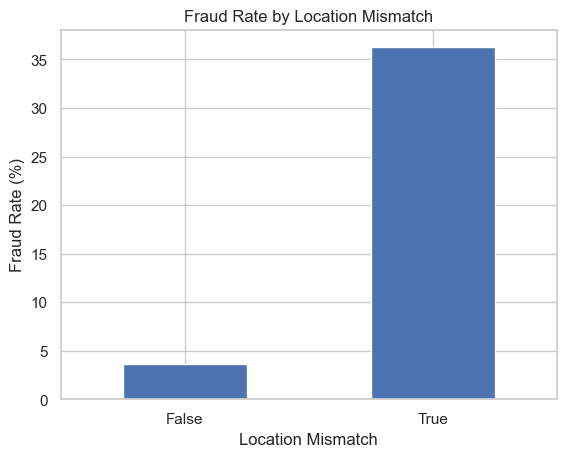

In [23]:
# Plotting Bivariate EDA to show relationship between location mismatch and target variable
fraud_rate = df.groupby('location_mismatch')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('Location Mismatch')
plt.title('Fraud Rate by Location Mismatch')
plt.xticks(rotation=0)
plt.show()

We can see that fraud rate is definetly higher in locations with true mismatch.

In [24]:
# listing all the categorical columns in the dataset

cat_cols=df.select_dtypes(include = ['object', 'category']).columns
cat_cols

Index(['transaction_id', 'customer_id', 'home_country', 'source_currency',
       'dest_currency', 'channel', 'device_id', 'ip_address', 'ip_country',
       'kyc_tier'],
      dtype='object')

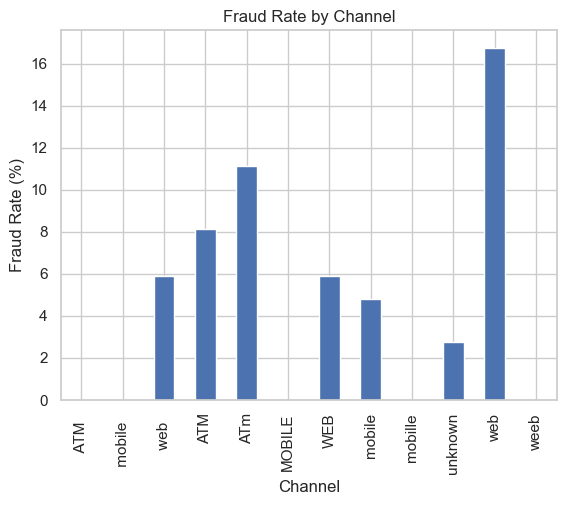

In [25]:
# Plotting Bivariate EDA to show relationship between channel and target variable
fraud_rate = df.groupby('channel')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('Channel')
plt.title('Fraud Rate by Channel')
plt.xticks(rotation=90)
plt.show()

In [26]:
# Checking unique values of the channel feature 
df['channel'].unique()

array(['ATM', 'web', 'mobile', 'WEB', ' web  ', 'MOBILE', 'unknown',
       'mobille', ' mobile  ', 'weeb', 'ATm', ' ATM  '], dtype=object)

In [27]:
# Removing white spaces in the channel feature 
df['channel'] = df['channel'].str.lower().str.strip()

In [28]:
# Checking unique values of the channel feature again
df['channel'].unique()

array(['atm', 'web', 'mobile', 'unknown', 'mobille', 'weeb'], dtype=object)

In [29]:
# Define mapping strategy for the channel feature 
# df['channel'] = df['channel'].str.lower().str.strip()

df['channel'] = df['channel'].replace({
    'mobille': 'mobile',
    'weeb': 'web'
})

df.loc[~df['channel'].isin(['atm', 'web', 'mobile', 'unknown']), 'channel'] = 'unknown'

In [30]:
# Checking unique values of the channel feature again
df['channel'].unique()

array(['atm', 'web', 'mobile', 'unknown'], dtype=object)

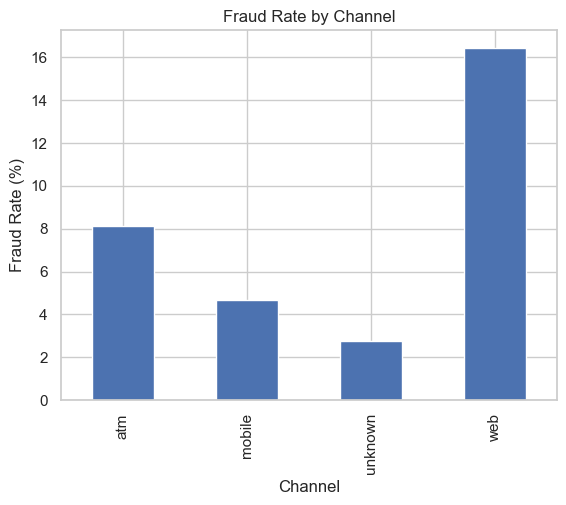

In [31]:
# Plotting Bivariate EDA to show relationship between channel and target variable
fraud_rate = df.groupby('channel')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('Channel')
plt.title('Fraud Rate by Channel')
plt.xticks(rotation=90)
plt.show()

Now, we can see from the cleaned and mapped plot that the channel with the highest fraud rate is web while the least is unknown

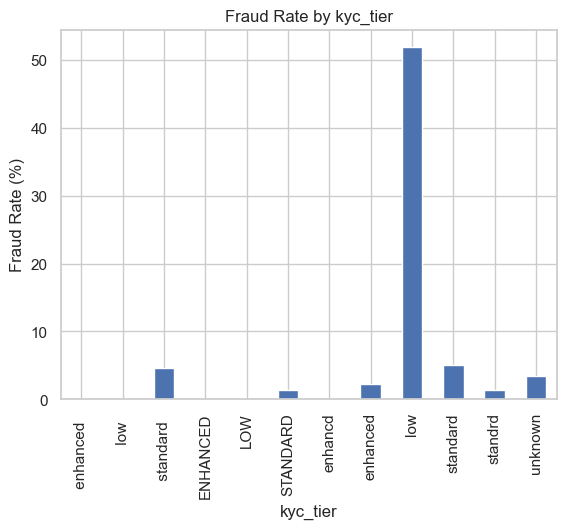

In [32]:
# Plotting Bivariate EDA to show relationship between kyc_tier and target variable
fraud_rate = df.groupby('kyc_tier')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('kyc_tier')
plt.title('Fraud Rate by kyc_tier')
plt.xticks(rotation=90)
plt.show()

In [33]:
# Checking unique values of the kyc_tier feature 
df['kyc_tier'].unique()

array(['standard', 'enhanced', 'low', ' standard  ', 'standrd',
       ' enhanced  ', 'STANDARD', 'unknown', 'enhancd', ' low  ',
       'ENHANCED', 'LOW'], dtype=object)

In [34]:
# Removing white spaces in the kyc_tier feature 
df['kyc_tier'] = df['kyc_tier'].str.lower().str.strip()

In [35]:
# Checking unique values of the kyc_tier feature again
df['kyc_tier'].unique()

array(['standard', 'enhanced', 'low', 'standrd', 'unknown', 'enhancd'],
      dtype=object)

In [36]:
# Define mapping strategy for the kyc_tier feature 

df['kyc_tier'] = df['kyc_tier'].replace({
    'standrd': 'standard',
    'enhancd': 'enhanced'
})

df.loc[~df['kyc_tier'].isin(['standard', 'enhanced', 'low', 'unknown']), 'kyc_tier'] = 'unknown'

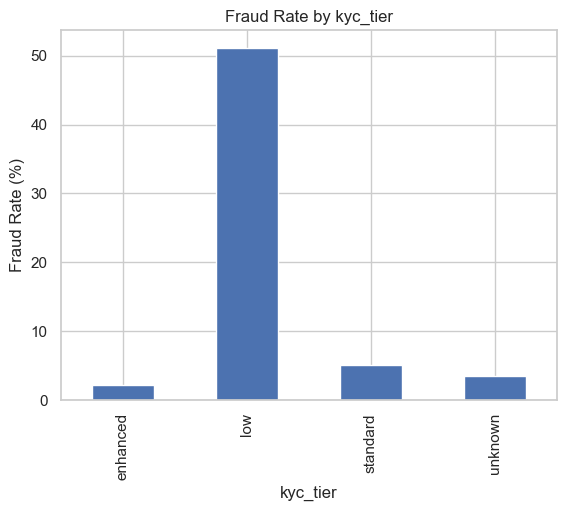

In [37]:
# Plotting Bivariate EDA to show relationship between kyc_tier and target variable
fraud_rate = df.groupby('kyc_tier')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('kyc_tier')
plt.title('Fraud Rate by kyc_tier')
plt.xticks(rotation=90)
plt.show()

From the Kyc_tier vs Target feature EDA, we can see that the most fradulent Kyc_tier is low while the least is enhanced.

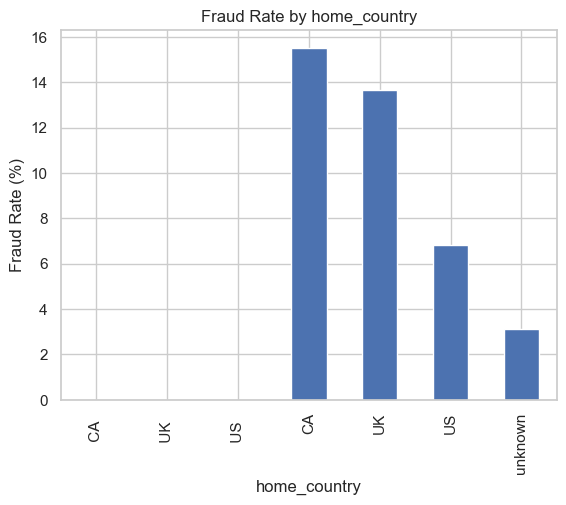

In [38]:
# Plotting Bivariate EDA to show relationship between home_country and target variable
fraud_rate = df.groupby('home_country')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('home_country')
plt.title('Fraud Rate by home_country')
plt.xticks(rotation=90)
plt.show()

In [39]:
# Checking unique values of the home_country feature 
df['home_country'].unique()

array(['US', 'CA', 'UK', ' UK  ', ' US  ', 'unknown', ' CA  '],
      dtype=object)

In [40]:
# Removing while spaces in the home_country feature 
df['home_country'] = df['home_country'].str.lower().str.strip()

In [41]:
# Checking unique values of the home_country feature again
df['home_country'].unique()

array(['us', 'ca', 'uk', 'unknown'], dtype=object)

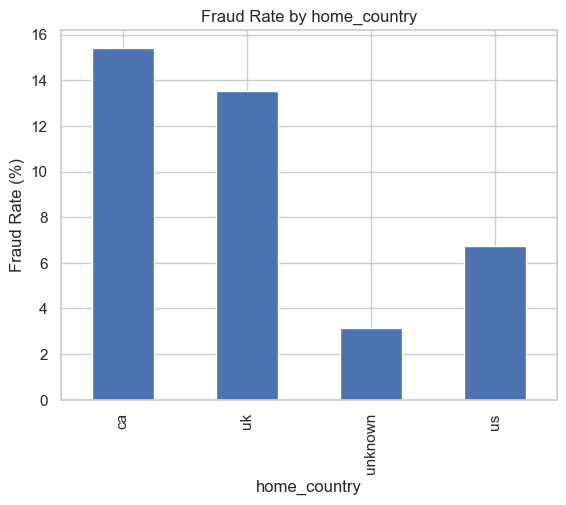

In [42]:
# Plotting Bivariate EDA to show relationship between home_country and target variable again
fraud_rate = df.groupby('home_country')['is_fraud'].mean() * 100

fraud_rate.plot(kind='bar')

plt.ylabel('Fraud Rate (%)')
plt.xlabel('home_country')
plt.title('Fraud Rate by home_country')
plt.xticks(rotation=90)
plt.show()

# Feature Engineering:

In [43]:
# Checking the components of the timestamp feature
df['timestamp'].unique()

<DatetimeArray>
['2022-10-03 18:40:59.468549+00:00', '2022-10-03 20:39:38.468549+00:00',
 '2022-10-03 23:02:43.468549+00:00', '2022-10-04 01:08:53.468549+00:00',
 '2022-10-04 09:35:03.468549+00:00', '2022-10-04 12:09:59.468549+00:00',
 '2022-10-04 12:37:41.468549+00:00', '2022-10-04 16:27:44.468549+00:00',
 '2022-10-04 21:00:36.468549+00:00', '2022-10-04 21:20:42.468549+00:00',
 ...
 '2025-11-24 13:42:17.573611+00:00', '2025-11-25 00:45:10.573611+00:00',
 '2025-11-25 07:44:29.573611+00:00', '2025-11-25 07:56:54.573611+00:00',
 '2025-11-25 09:48:28.573611+00:00', '2025-11-25 10:05:35.573611+00:00',
 '2025-11-26 07:09:56.573611+00:00', '2025-11-27 06:19:11.573611+00:00',
 '2025-11-28 00:53:28.573611+00:00', '2025-11-29 20:10:47.573611+00:00']
Length: 10835, dtype: datetime64[ns, UTC]

In [44]:
# Separating/Converting the timestamp feature into date, time and days of the week
df['hour']=df['timestamp'].dt.hour
df['day_of_week']=df['timestamp'].dt.dayofweek
df['is_weekend']=(df['day_of_week'] >= 5).astype(int)

print("Time Features Created: ")
print(df[['timestamp', 'hour', 'day_of_week', 'is_weekend']].head())
print("\n Hour Distribution")
print(df['hour'].value_counts().sort_index())

Time Features Created: 
                         timestamp  hour  day_of_week  is_weekend
0 2022-10-03 18:40:59.468549+00:00    18            0           0
1 2022-10-03 20:39:38.468549+00:00    20            0           0
2 2022-10-03 23:02:43.468549+00:00    23            0           0
3 2022-10-04 01:08:53.468549+00:00     1            1           0
4 2022-10-04 09:35:03.468549+00:00     9            1           0

 Hour Distribution
hour
0     462
1     403
2     420
3     490
4     509
5     484
6     470
7     452
8     483
9     436
10    459
11    438
12    456
13    460
14    424
15    473
16    469
17    438
18    474
19    504
20    450
21    432
22    457
23    487
Name: count, dtype: int64


hour
0      6.277056
1      6.451613
2      7.857143
3     12.448980
4     18.467583
5     15.909091
6     21.063830
7     18.141593
8     12.629400
9      4.587156
10     6.971678
11     7.762557
12     6.140351
13     6.521739
14     7.783019
15     5.919662
16     6.396588
17     5.022831
18     7.805907
19     4.563492
20     6.000000
21     7.870370
22     5.689278
23     4.312115
Name: is_fraud, dtype: float64


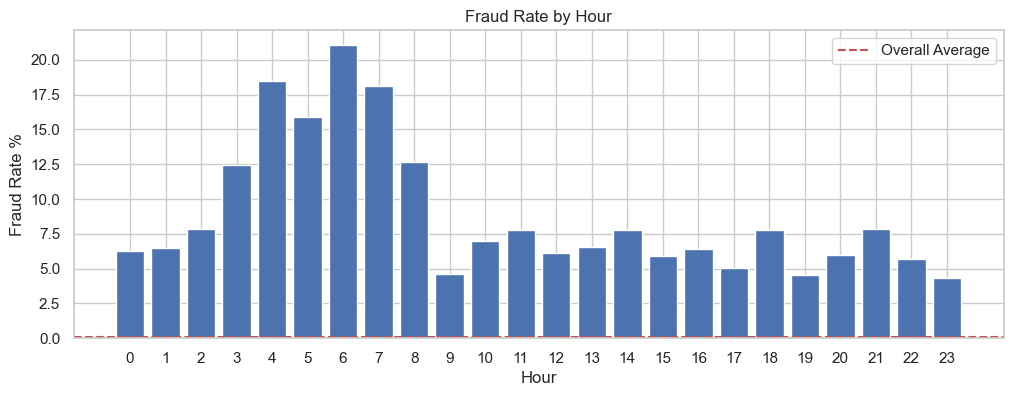

In [45]:
# Checking fraud rate per hour
fraud_by_hour = df.groupby('hour')['is_fraud'].mean()*100
print(fraud_by_hour)

plt.figure(figsize=(12, 4))
plt.bar(fraud_by_hour.index, fraud_by_hour.values)

plt.xlabel('Hour')
plt.ylabel('Fraud Rate %')
plt.title('Fraud Rate by Hour')

plt.axhline(
    y=df['is_fraud'].mean(),
    color='r',
    linestyle='--',
    label='Overall Average'
)

plt.legend()
plt.xticks(range(0, 24))
plt.show()

We can see from the plot fraud mostly occur during the early hours of the day between 3am and 8am in the morning.

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11030 entries, 0 to 11399
Data columns (total 32 columns):
 #   Column                           Non-Null Count  Dtype              
---  ------                           --------------  -----              
 0   transaction_id                   11030 non-null  object             
 1   customer_id                      11030 non-null  object             
 2   timestamp                        11030 non-null  datetime64[ns, UTC]
 3   home_country                     11030 non-null  object             
 4   source_currency                  11030 non-null  object             
 5   dest_currency                    11030 non-null  object             
 6   channel                          11030 non-null  object             
 7   amount_src                       11030 non-null  float64            
 8   amount_usd                       11030 non-null  float64            
 9   fee                              11030 non-null  float64            
 10  exc

In [47]:
df['account_age_days'].describe()

count    11030.000000
mean       393.040435
std        342.055887
min          1.000000
25%        147.000000
50%        286.500000
75%        661.000000
max       1095.000000
Name: account_age_days, dtype: float64

age_bucket
<30d>       36.076964
30-90d      44.180523
90-180d      2.309237
180-365d     1.652661
>1yr         1.054650
Name: is_fraud, dtype: float64


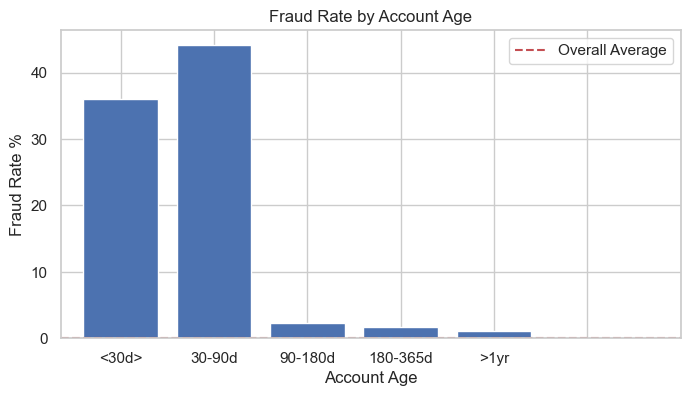

In [48]:
# checking fraud rate by account age buckets
df['age_bucket']=pd.cut(df['account_age_days'],
                        bins=(0, 30, 90, 180, 365, 2000),
                        labels=['<30d>', '30-90d', '90-180d', '180-365d', '>1yr'])

fraud_by_age = df.groupby('age_bucket')['is_fraud'].mean()*100
print(fraud_by_age)

plt.figure(figsize=(8, 4))
plt.bar(range(len(fraud_by_age)), fraud_by_age.values)
plt.xticks(range(len(fraud_by_age)), fraud_by_age.index)

plt.xlabel('Account Age')
plt.ylabel('Fraud Rate %')
plt.title('Fraud Rate by Account Age')

plt.axhline(
    y=df['is_fraud'].mean(),
    color='r',
    linestyle='--',
    label='Overall Average'
)

plt.legend()
plt.xticks(range(0, 7))
plt.show()

We can see from the plot that the most fraud happened on accounts opened or operated with 30-90days, followed by accounts opened or operated in less than 30 days while the least was on accounts opened or operated over a year.

txn_velocity_1h
-1     2.105263
 0     1.756027
 1     0.000000
 2     0.000000
 3    83.587786
 4    84.232365
 5    80.104712
 6    70.000000
 7    70.270270
 8    47.727273
Name: is_fraud, dtype: float64


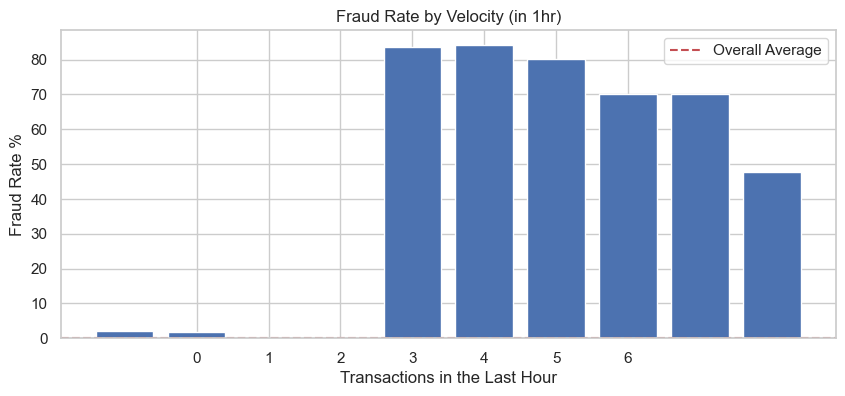

In [49]:
# Checking fraud by velocity (i.e transaction in last hour)
fraud_by_velocity = df.groupby('txn_velocity_1h')['is_fraud'].mean()*100
print(fraud_by_velocity)

plt.figure(figsize=(10, 4))
plt.bar(fraud_by_velocity.index, fraud_by_velocity.values)

plt.xlabel('Transactions in the Last Hour')
plt.ylabel('Fraud Rate %')
plt.title('Fraud Rate by Velocity (in 1hr)')

plt.axhline(
    y=df['is_fraud'].mean(),
    color='r',
    linestyle='--',
    label='Overall Average'
)

plt.legend()
plt.xticks(range(0, 7))
plt.show()

amount_bucket
<$100        1.817002
$100-500     6.067073
$500-1k     29.520295
$1k-2k      67.169811
$2k-5k      94.382022
$5k-20k     14.027149
Name: is_fraud, dtype: float64


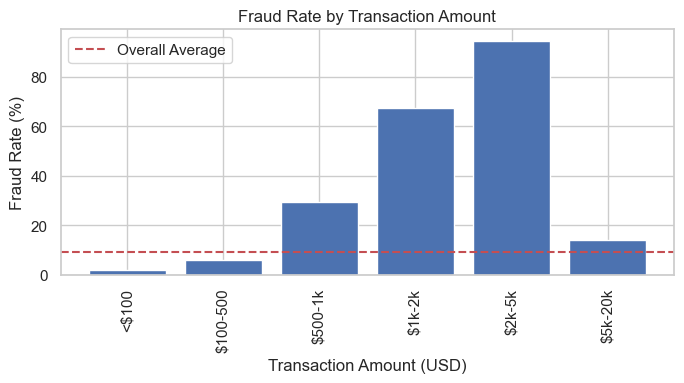

In [50]:
# Checking fraud rate by amount bucket 

# Create amount buckets
df['amount_bucket'] = pd.cut(
    df['amount_usd'],
    bins=[0, 100, 500, 1000, 2000, 5000, 20000],
    labels=['<$100', '$100-500', '$500-1k', '$1k-2k', '$2k-5k', '$5k-20k'],
    include_lowest=True
)

# Calculate fraud rate per bucket (percentage)
fraud_by_amount = df.groupby('amount_bucket')['is_fraud'].mean() * 100
print(fraud_by_amount)

# Plot
plt.figure(figsize=(7, 4))
plt.bar(fraud_by_amount.index.astype(str), fraud_by_amount.values)

plt.xlabel('Transaction Amount (USD)')
plt.ylabel('Fraud Rate (%)')
plt.title('Fraud Rate by Transaction Amount')

plt.axhline(
    y=df['is_fraud'].mean() * 100,
    color='r',
    linestyle='--',
    label='Overall Average'
)

plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

From the plot above, we can see that the most fraud occured in the $2k-$5k amount bucket, followed by the $1k-2k bucket while the <$100 amount bucket was least.  

In [51]:
# checking if there's a relationship between the ip_risk_score feature and the target feature
df['ip_risk_score'].describe()

count    11030.000000
mean         0.397463
std          0.270972
min          0.004000
25%          0.209000
50%          0.325000
75%          0.488000
max          1.200000
Name: ip_risk_score, dtype: float64

There's a relationship because the min value = 0.004 and max value is 1.20

ip_risk_bucket
low-0.3      1.492236
0.3-0.5      2.235772
0.5-0.7      2.930057
0.7-0.8     19.148936
High>0.8    62.520194
Name: is_fraud, dtype: float64


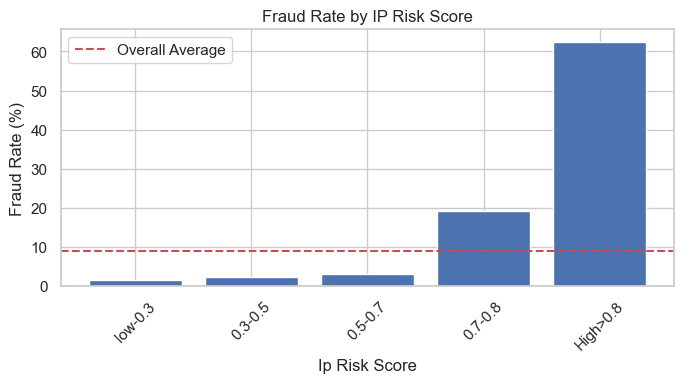

In [52]:
# Checking fraud rate by 'ip_risk_score bucket'

# Create amount buckets
df['ip_risk_bucket'] = pd.cut(
    df['ip_risk_score'],
    bins=[0, 0.3, 0.5, 0.7, 0.8, 1.0],
    labels=['low-0.3', '0.3-0.5', '0.5-0.7', '0.7-0.8', 'High>0.8'],
    include_lowest=True
)

# Calculate fraud rate per bucket (percentage)
fraud_by_ip = df.groupby('ip_risk_bucket')['is_fraud'].mean() * 100
print(fraud_by_ip)

# Plot
plt.figure(figsize=(7, 4))
plt.bar(range(len(fraud_by_ip)), fraud_by_ip.values)
plt.xticks(range(len(fraud_by_ip)), fraud_by_ip.index)

plt.xlabel('Ip Risk Score')
plt.ylabel('Fraud Rate (%)')
plt.title('Fraud Rate by IP Risk Score')

plt.axhline(
    y=df['is_fraud'].mean() * 100,
    color='r',
    linestyle='--',
    label='Overall Average'
)

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

We can see that obviously, Ip risk score of High>0.8 had the most fraud while the least was low-0.3

In [53]:
# checking if there's a relationship between the ip_risk_score feature and the target feature
df['device_trust_score'].describe()

count    11030.000000
mean         0.654513
std          0.272037
min         -0.100000
25%          0.515000
50%          0.658000
75%          0.894000
max          0.999000
Name: device_trust_score, dtype: float64

There's a relationship between the device_trust_score feature and the target feature because of the gap between the min and max numbers.

device_trust_bucket
low-0.3     84.626039
0.3-0.5     11.129754
0.5-0.7      2.025847
0.7-0.9      3.271841
High>0.9     0.809561
Name: is_fraud, dtype: float64


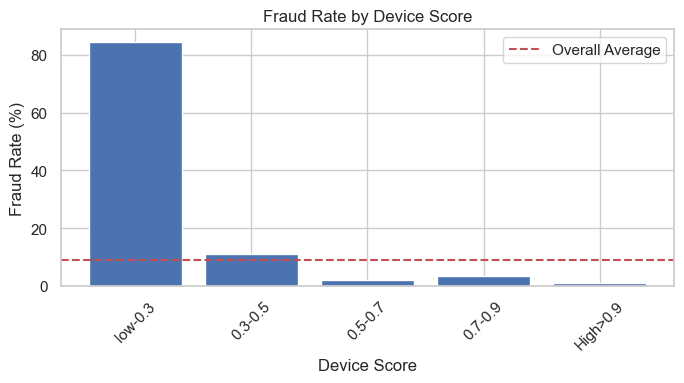

In [54]:
# Checking fraud rate by 'device trust bucket'

# Create amount buckets
df['device_trust_bucket'] = pd.cut(
    df['device_trust_score'],
    bins=[0, 0.3, 0.5, 0.7, 0.9, 1.0],
    labels=['low-0.3', '0.3-0.5', '0.5-0.7', '0.7-0.9', 'High>0.9'],
    include_lowest=True
)

# Calculate fraud rate per bucket (percentage)
fraud_by_device_score = df.groupby('device_trust_bucket')['is_fraud'].mean() * 100
print(fraud_by_device_score)

# Plot
plt.figure(figsize=(7, 4))
plt.bar(range(len(fraud_by_device_score)), fraud_by_device_score.values)
plt.xticks(range(len(fraud_by_device_score)), fraud_by_device_score.index)

plt.xlabel('Device Score')
plt.ylabel('Fraud Rate (%)')
plt.title('Fraud Rate by Device Score')

plt.axhline(
    y=df['is_fraud'].mean() * 100,
    color='r',
    linestyle='--',
    label='Overall Average'
)

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

We can see that obviously, device score of low-0.3 had the most fraud while the least was High>0.9 

In [55]:
# Based on our analysis, we create threshold based features:
df['night_hours']=((df['hour']>=3) & (df['hour']<=7)).astype(int)
df['account_very_low']=(df['account_age_days']<30).astype(int)
df['account_new']=((df['account_age_days']>=30) & (df['account_age_days']<90)).astype(int)
df['velocity_burst']=(df['txn_velocity_1h']>=3).astype(int)
df['amount_high']=(df['amount_usd']>=2000).astype(int)
df['ip_high_risk']=(df['ip_risk_score']>=0.8).astype(int)
df['device_low_trust']=(df['device_trust_score']<0.5).astype(int)

In [56]:
df.head(10)

,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,exchange_rate_src_to_dest,device_id,new_device,ip_address,ip_country,location_mismatch,ip_risk_score,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud,ip_country_missing_flag,kyc_tier_missing_flag,device_trust_score_missing_flag,hour,day_of_week,is_weekend,age_bucket,amount_bucket,ip_risk_bucket,device_trust_bucket,night_hours,account_very_low,account_new,velocity_burst,amount_high,ip_high_risk,device_low_trust
0,fee8542d-8ee6-4b0d-9671-c294dd08ed26,402cccc9-28de-45b3-9af7-cc5302aa1f93,2022-10-03 18:40:59.468549+00:00,us,USD,CAD,atm,278.19,278.19,4.25,1.351351,9f292dcc-3297-4947-a260-6a1ef69041ff,False,221.78.171.180,US,False,0.123,standard,263,0.522,0,0.223,0,0,0.00,0,0,0,0,18,0,0,180-365d,$100-500,low-0.3,0.5-0.7,0,0,0,0,0,0,0
1,bfdb9fc1-27fe-4a85-b043-4d813d679259,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-10-03 20:39:38.468549+00:00,ca,CAD,MXN,web,208.51,154.29,4.24,12.758621,3a95b9f5-309f-4684-a46d-e2ff2435bf78,True,120.12.20.29,CA,False,0.569,standard,947,0.475,0,0.268,0,1,0.00,0,0,0,0,20,0,0,>1yr,$100-500,0.5-0.7,0.3-0.5,0,0,0,0,0,0,1
2,fc855034-3ea5-4993-9afa-b511d93fe5e8,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-10-03 23:02:43.468549+00:00,us,USD,CNY,mobile,160.33,160.33,2.70,7.142857,a4737752-9aac-43ed-9d8b-2ccdffc24052,False,223.96.181.93,US,False,0.437,enhanced,367,0.939,0,0.176,0,0,0.00,0,0,0,0,23,0,0,>1yr,$100-500,0.3-0.5,High>0.9,0,0,0,0,0,0,0
3,2cf8c08e-42ec-444d-a755-34b9a2a0a4ca,7bd5200c-5d19-44f0-9afe-8b339a05366b,2022-10-04 01:08:53.468549+00:00,us,USD,EUR,mobile,59.41,59.41,2.22,0.925926,6aeb85a3-5603-4221-896c-9e6882764f1a,False,186.228.15.74,US,False,0.594,standard,147,0.551,0,0.391,0,0,0.00,0,0,0,0,1,1,0,90-180d,<$100,0.5-0.7,0.5-0.7,0,0,0,0,0,0,0
4,d907a74d-b426-438d-97eb-dbe911aca91c,70a93d26-8e3a-4179-900c-a4a7a74d08e5,2022-10-04 09:35:03.468549+00:00,us,USD,INR,mobile,200.96,200.96,3.61,83.333333,a5b9250e-dbe0-4c5f-a6e7-5492b7349402,False,11.82.47.62,US,False,0.121,enhanced,257,0.894,0,0.257,0,0,0.00,0,0,0,0,9,1,0,180-365d,$100-500,low-0.3,0.7-0.9,0,0,0,0,0,0,0
5,ec17d6f2-6505-4de9-910f-0de3ac3bbc23,4cfe5cbc-d677-49bc-8739-b1d05f351250,2022-10-04 12:09:59.468549+00:00,us,USD,GBP,mobile,526.90,526.90,8.75,0.800000,209e3bb0-50ea-49b7-a681-036adf7b1251,False,191.142.136.198,US,False,0.094,low,616,0.702,0,0.361,0,0,0.00,0,0,0,0,12,1,0,>1yr,$500-1k,low-0.3,0.7-0.9,0,0,0,0,0,0,0
6,2d8efe37-33ea-40de-9881-e553e3f2f8ce,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-10-04 12:37:41.468549+00:00,ca,CAD,GBP,mobile,149.24,110.44,2.33,0.592000,cd539961-17ad-4f6b-94ae-8080423af5e3,False,106.34.98.71,CA,False,0.299,standard,947,0.625,0,0.268,0,0,0.00,0,0,0,0,12,1,0,>1yr,$100-500,low-0.3,0.5-0.7,0,0,0,0,0,0,0
7,4d311532-ee0b-4985-b996-63e11a7144d3,4dfeffe2-94ed-4fc3-b5bc-89c6f1e86dab,2022-10-04 16:27:44.468549+00:00,ca,CAD,INR,web,276.51,204.62,5.59,61.666667,96468499-b7b2-4273-a946-dbf2cb7dc95a,False,32.170.54.208,CA,False,0.087,standard,1041,0.867,0,0.245,0,1,0.12,0,0,0,0,16,1,0,>1yr,$100-500,low-0.3,0.7-0.9,0,0,0,0,0,0,0
8,db5bdea7-0701-4c07-9efa-815fa6ca9ede,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-10-04 21:00:36.468549+00:00,us,USD,EUR,mobile,99.52,99.52,2.41,0.925926,3c27e832-cb50-4fc5-b782-ec97f6a5d50c,False,109.242.237.91,US,False,0.182,enhanced,367,0.939,0,0.176,0,0,0.00,0,0,0,0,21,1,0,>1yr,<$100,low-0.3,High>0.9,0,0,0,0,0,0,0
9,d74c81c0-bf5d-4184-8ce2-27fb753cb1c6,f7531a78-8bbe-4a85-b1e8-a0650edddc72,2022-10-04 21:20:42.468549+00:00,us,USD,PHP,web,302.55,302.55,5.26,58.823529,3df8c73d-b716-4a6e-8172-d2b7359b60b2,False,103.237.21.29,US,False,0.413,standard,1016,0.944,0,0.247,0,0,0.10,1,0,0,0,21,1,0,>1yr,$100-500,0.3-0.5,High>0.9,0,0,0,0,0,0,0


# Feature Selection:

In [57]:
# Drop off temporary bucket column and select final features 
df=df.drop(['age_bucket', 'amount_bucket', 'ip_risk_bucket', 'device_trust_bucket'], axis=1)

In [58]:
df.columns

Index(['transaction_id', 'customer_id', 'timestamp', 'home_country',
       'source_currency', 'dest_currency', 'channel', 'amount_src',
       'amount_usd', 'fee', 'exchange_rate_src_to_dest', 'device_id',
       'new_device', 'ip_address', 'ip_country', 'location_mismatch',
       'ip_risk_score', 'kyc_tier', 'account_age_days', 'device_trust_score',
       'chargeback_history_count', 'risk_score_internal', 'txn_velocity_1h',
       'txn_velocity_24h', 'corridor_risk', 'is_fraud',
       'ip_country_missing_flag', 'kyc_tier_missing_flag',
       'device_trust_score_missing_flag', 'hour', 'day_of_week', 'is_weekend',
       'night_hours', 'account_very_low', 'account_new', 'velocity_burst',
       'amount_high', 'ip_high_risk', 'device_low_trust'],
      dtype='object')

In [59]:
# Defining feature sets 

numerical_features=['channel', 'kyc_tier', 'home_country', 'source_currency', 'dest_currency', 'ip_country', 
                    'new_device', 'location_mismatch']

categorical_features=['amount_src', 'amount_usd', 'fee', 'ip_risk_score', 'device_trust_score', 'account_age_days', 
                      'txn_velocity_1h', 'txn_velocity_24h', 'corridor_risk', 'risk_score_internal', 'hour', 'day_of_week',
                      'is_weekend', 'night_hours', 'account_new', 'velocity_burst', 'amount_high',
                      'ip_high_risk', 'device_low_trust']

In [60]:
# Concatinating/creating all features 
all_features=categorical_features+numerical_features

print(f"\nTotal Features: {len(all_features)}")
print(f"Categorical Features: {len(categorical_features)}")
print(f"Numerical Features: {len(numerical_features)}")
print(f"\nDataset Shape: {df.shape}")


Total Features: 27
Categorical Features: 19
Numerical Features: 8

Dataset Shape: (11030, 39)


# Model Split & Training:

In [61]:
# Sort by timestamp for chronological split
df=df.sort_values('timestamp').reset_index(drop=True)

# 80/20 time-based split
split_idx=int(len(df)*0.8)
train_df=df.iloc[:split_idx].copy()
test_df=df.iloc[split_idx:].copy()

print(f"Train: {len(train_df)} rows ({train_df['is_fraud'].sum()} fraud, {train_df['is_fraud'].mean():.3f} rate)")
print(f"Test: {len(test_df)} rows ({test_df['is_fraud'].sum()} fraud, {test_df['is_fraud'].mean():.3f} rate)")

# Prepare X and y variables
X_train=train_df[all_features]
y_train=train_df['is_fraud']
X_test=test_df[all_features]
y_test=test_df['is_fraud']

print(f"\nX_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"\nX_test: {X_test.shape}, y_test: {y_test.shape}")

Train: 8824 rows (679 fraud, 0.077 rate)
Test: 2206 rows (308 fraud, 0.140 rate)

X_train: (8824, 27), y_train: (8824,)

X_test: (2206, 27), y_test: (2206,)


In [62]:
# 1) Ensure timestamp is datetime
df = df.copy()
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# Drop rows with missing timestamps (or decide how to handle them)
df = df.dropna(subset=["timestamp"])

# 2) Sort chronologically
df = df.sort_values("timestamp").reset_index(drop=True)

# 3) 80/20 time-based split
split_idx = int(len(df) * 0.8)

train_df = df.iloc[:split_idx].copy()
test_df  = df.iloc[split_idx:].copy()

# 4) Sanity checks
assert "is_fraud" in df.columns, "Missing target column: is_fraud"
assert isinstance(all_features, (list, tuple)) and len(all_features) > 0, "all_features must be a non-empty list"

# Prevent leakage: target must not be in features
assert "is_fraud" not in all_features, "Leakage: 'is_fraud' included in all_features"

# Prevent missing-feature crashes
missing = [c for c in all_features if c not in df.columns]
assert len(missing) == 0, f"These features are missing from df: {missing}"

# 5) Prepare X and y
X_train = train_df[all_features]
y_train = train_df["is_fraud"].astype(int)

X_test  = test_df[all_features]
y_test  = test_df["is_fraud"].astype(int)

print(f"Train: {len(train_df)} rows ({y_train.sum()} fraud, {y_train.mean():.3f} rate)")
print(f"Test : {len(test_df)} rows ({y_test.sum()} fraud, {y_test.mean():.3f} rate)")
print(f"\nX_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}, y_test : {y_test.shape}")

# Optional: confirm no time overlap
print("\nTrain time range:", train_df["timestamp"].min(), "->", train_df["timestamp"].max())
print("Test  time range:", test_df["timestamp"].min(), "->", test_df["timestamp"].max())

Train: 8824 rows (679 fraud, 0.077 rate)
Test : 2206 rows (308 fraud, 0.140 rate)

X_train: (8824, 27), y_train: (8824,)
X_test : (2206, 27), y_test : (2206,)

Train time range: 2022-10-03 18:40:59.468549+00:00 -> 2025-03-23 22:28:39.468549+00:00
Test  time range: 2025-03-24 01:20:38.468549+00:00 -> 2025-12-16 00:13:41.468549+00:00


In [63]:
# Checking all column names
df.columns

Index(['transaction_id', 'customer_id', 'timestamp', 'home_country',
       'source_currency', 'dest_currency', 'channel', 'amount_src',
       'amount_usd', 'fee', 'exchange_rate_src_to_dest', 'device_id',
       'new_device', 'ip_address', 'ip_country', 'location_mismatch',
       'ip_risk_score', 'kyc_tier', 'account_age_days', 'device_trust_score',
       'chargeback_history_count', 'risk_score_internal', 'txn_velocity_1h',
       'txn_velocity_24h', 'corridor_risk', 'is_fraud',
       'ip_country_missing_flag', 'kyc_tier_missing_flag',
       'device_trust_score_missing_flag', 'hour', 'day_of_week', 'is_weekend',
       'night_hours', 'account_very_low', 'account_new', 'velocity_burst',
       'amount_high', 'ip_high_risk', 'device_low_trust'],
      dtype='object')

In [64]:
# Define features (drop IDs + raw timestamp + raw IP)

TARGET = "is_fraud"

DROP_COLS = [
    TARGET,
    "transaction_id",
    "customer_id",
    "device_id",
    "timestamp",
    "ip_address"
]

feature_cols = [c for c in train_df.columns if c not in DROP_COLS]

X_train = train_df[feature_cols].copy()
y_train = train_df[TARGET].astype(int).copy()

X_test  = test_df[feature_cols].copy()
y_test  = test_df[TARGET].astype(int).copy()

print("Features:", len(feature_cols))
print("Train fraud rate:", y_train.mean(), "Test fraud rate:", y_test.mean())


Features: 33
Train fraud rate: 0.07694922937443337 Test fraud rate: 0.13961922030825022


In [65]:
# Building the data pre-processing pipelines.

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Detect numeric vs categorical
num_cols = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]

print("Numeric:", len(num_cols), "Categorical:", len(cat_cols))
print("Categorical columns:", cat_cols)

numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False))  # safe with sparse matrices
])

categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, num_cols),
        ("cat", categorical_pipe, cat_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

Numeric: 27 Categorical: 6
Categorical columns: ['home_country', 'source_currency', 'dest_currency', 'channel', 'ip_country', 'kyc_tier']


In [66]:
# Building the Models 

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# class imbalance handling
pos = int(y_train.sum())
neg = int((y_train == 0).sum())
scale_pos_weight = (neg / max(pos, 1))

models = {
    "LogisticRegression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced"
    ),
    "DecisionTree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced",
        max_depth=None,
        min_samples_leaf=50
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=400,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced_subsample",
        min_samples_leaf=30
    ),
    "XGBoost": XGBClassifier(
        n_estimators=800,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1,
        scale_pos_weight=scale_pos_weight
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=1200,
        learning_rate=0.03,
        num_leaves=63,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )
}

In [67]:
# Unified train + evaluate pipeline 

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, classification_report, confusion_matrix
)

def fit_and_evaluate(name, model, X_train, y_train, X_test, y_test, preprocess, target_recall=0.80):
    pipe = Pipeline(steps=[
        ("preprocess", preprocess),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    # Probabilities
    proba = pipe.predict_proba(X_test)[:, 1]

    roc = roc_auc_score(y_test, proba)
    pr  = average_precision_score(y_test, proba)

    # Threshold tuning for recall target (fraud-friendly)
    precision, recall, thresholds = precision_recall_curve(y_test, proba)

    # precision/recall arrays have one extra element vs thresholds
    valid = np.where(recall[:-1] >= target_recall)[0]
    if len(valid) == 0:
        best_idx = np.argmax(precision[:-1])  # fallback if recall target impossible
    else:
        best_idx = valid[np.argmax(precision[valid])]

    best_thr = thresholds[best_idx]
    preds = (proba >= best_thr).astype(int)

    cm = confusion_matrix(y_test, preds)
    report = classification_report(y_test, preds, digits=4)

    out = {
        "model": name,
        "ROC_AUC": roc,
        "PR_AUC": pr,
        "threshold": float(best_thr),
        "precision@thr": float(precision[best_idx]),
        "recall@thr": float(recall[best_idx]),
        "confusion_matrix": cm,
        "report": report,
        "pipeline": pipe
    }
    return out


results = []
pipelines = {}

for name, model in models.items():
    res = fit_and_evaluate(name, model, X_train, y_train, X_test, y_test, preprocess, target_recall=0.80)
    results.append({
        "model": res["model"],
        "ROC_AUC": res["ROC_AUC"],
        "PR_AUC": res["PR_AUC"],
        "threshold": res["threshold"],
        "precision@thr": res["precision@thr"],
        "recall@thr": res["recall@thr"]
    })
    pipelines[name] = res["pipeline"]
    print("\n" + "="*70)
    print(name)
    print(f"ROC_AUC={res['ROC_AUC']:.4f}  PR_AUC={res['PR_AUC']:.4f}  thr={res['threshold']:.4f}")
    print("Confusion matrix:\n", res["confusion_matrix"])
    print(res["report"])

results_df = pd.DataFrame(results).sort_values("PR_AUC", ascending=False)
results_df


LogisticRegression
ROC_AUC=0.9828  PR_AUC=0.9670  thr=0.9122
Confusion matrix:
 [[1898    0]
 [  24  284]]
              precision    recall  f1-score   support

           0     0.9875    1.0000    0.9937      1898
           1     1.0000    0.9221    0.9595       308

    accuracy                         0.9891      2206
   macro avg     0.9938    0.9610    0.9766      2206
weighted avg     0.9893    0.9891    0.9889      2206


DecisionTree
ROC_AUC=0.9677  PR_AUC=0.9456  thr=0.9947
Confusion matrix:
 [[1898    0]
 [  42  266]]
              precision    recall  f1-score   support

           0     0.9784    1.0000    0.9891      1898
           1     1.0000    0.8636    0.9268       308

    accuracy                         0.9810      2206
   macro avg     0.9892    0.9318    0.9579      2206
weighted avg     0.9814    0.9810    0.9804      2206


RandomForest
ROC_AUC=0.9786  PR_AUC=0.9638  thr=0.7912
Confusion matrix:
 [[1898    0]
 [  25  283]]
              precision    recall 

,model,ROC_AUC,PR_AUC,threshold,precision@thr,recall@thr
0,LogisticRegression,0.982813,0.967027,0.912211,1.0,0.922078
2,RandomForest,0.978568,0.963758,0.791215,1.0,0.918831
3,XGBoost,0.972327,0.954220,0.987624,1.0,0.918831
4,LightGBM,0.969154,0.950079,0.999978,1.0,0.912338
1,DecisionTree,0.967673,0.945602,0.994707,1.0,0.863636


In [68]:
# Selecting the best model 

best_name = results_df.iloc[0]["model"]
best_pipe = pipelines[best_name]
print("Best model by PR-AUC:", best_name)

import joblib
joblib.dump(best_pipe, "novapay_fraud_model_pipeline.pkl")
print("Saved: novapay_fraud_model_pipeline.pkl")

Best model by PR-AUC: LogisticRegression
Saved: novapay_fraud_model_pipeline.pkl


In [69]:
# Checking for feature importance of the best model 

best_model_obj = best_pipe.named_steps["model"]
print(type(best_model_obj))

# Works for RF/DT/LGBM/XGB (not for LR in same way)
if hasattr(best_model_obj, "feature_importances_"):
    importances = best_model_obj.feature_importances_
    print("Num importances:", len(importances))
    # Note: with OneHot, mapping back to feature names requires get_feature_names_out()
    feat_names = best_pipe.named_steps["preprocess"].get_feature_names_out()
    fi = (pd.DataFrame({"feature": feat_names, "importance": importances})
            .sort_values("importance", ascending=False)
            .head(30))
    fi

<class 'sklearn.linear_model._logistic.LogisticRegression'>


# Hyperparameter Tuning:

In [70]:
# Time-based CV + metric

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score
import numpy as np

tscv = TimeSeriesSplit(n_splits=5)  
SCORING = "average_precision"       # PR-AUC
RANDOM_STATE = 42

In [71]:
# Helper to run tunining for a model

def tune_model(model, param_distributions, X_train, y_train, preprocess,
               n_iter=30, cv=tscv, scoring=SCORING, random_state=RANDOM_STATE, n_jobs=-1):

    pipe = Pipeline(steps=[
        ("preprocess", preprocess),
        ("model", model)
    ])

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring=scoring,
        cv=cv,
        verbose=1,
        random_state=random_state,
        n_jobs=n_jobs,
        refit=True
    )

    search.fit(X_train, y_train)
    return search

In [72]:
# Tuning the models

# Logistic Regression:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=4000, class_weight="balanced")

lr_params = {
    "model__C": np.logspace(-3, 2, 20),
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"]
}

# Decision Tree:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced")

dt_params = {
    "model__max_depth": [None, 3, 5, 7, 10, 15, 20],
    "model__min_samples_split": [2, 10, 50, 200, 500],
    "model__min_samples_leaf": [1, 5, 10, 30, 50, 100],
    "model__ccp_alpha": np.linspace(0.0, 0.02, 10)
}

# Random Forest:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced_subsample"
)

rf_params = {
    "model__n_estimators": [300, 500, 800, 1200],
    "model__max_depth": [None, 8, 12, 16, 20],
    "model__min_samples_leaf": [5, 10, 20, 40, 80],
    "model__min_samples_split": [2, 10, 50, 200],
    "model__max_features": ["sqrt", "log2", 0.5, 0.8]
}

# XGBoost:

from xgboost import XGBClassifier

pos = int(y_train.sum())
neg = int((y_train == 0).sum())
scale_pos_weight = neg / max(pos, 1)

xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight
)

xgb_params = {
    "model__n_estimators": [400, 700, 1000, 1500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__subsample": [0.6, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__min_child_weight": [1, 5, 10, 20],
    "model__gamma": [0, 0.1, 0.3, 1.0],
    "model__reg_lambda": [0.5, 1.0, 2.0, 5.0]
}


# LightGBM
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"
)

lgbm_params = {
    "model__n_estimators": [500, 800, 1200, 2000],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__num_leaves": [31, 63, 127, 255],
    "model__max_depth": [-1, 5, 8, 12, 16],
    "model__min_child_samples": [10, 20, 50, 100, 200],
    "model__subsample": [0.6, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__reg_lambda": [0.0, 0.5, 1.0, 2.0, 5.0]
}

In [73]:
# Tuning Logistic Regression Model:
lr_search   = tune_model(lr,   lr_params,   X_train, y_train, preprocess, n_iter=20)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


In [74]:
# Tuning Decision Tree Model:
dt_search   = tune_model(dt,   dt_params,   X_train, y_train, preprocess, n_iter=30)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [75]:
# Tuning Random Forest Model:
rf_search   = tune_model(rf,   rf_params,   X_train, y_train, preprocess, n_iter=30)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [76]:
# Tuning XGBoost model:
xgb_search  = tune_model(xgb,  xgb_params,  X_train, y_train, preprocess, n_iter=35)

Fitting 5 folds for each of 35 candidates, totalling 175 fits


In [77]:
# Tuning LightGBM model
lgbm_search = tune_model(lgbm, lgbm_params, X_train, y_train, preprocess, n_iter=35)

Fitting 5 folds for each of 35 candidates, totalling 175 fits
[LightGBM] [Info] Number of positive: 679, number of negative: 8145
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002854 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1851
[LightGBM] [Info] Number of data points in the train set: 8824, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


In [78]:
# Comparing tuned models on my held-out future test set
from sklearn.metrics import roc_auc_score, average_precision_score

searches = {
    "LogReg_tuned": lr_search,
    "DT_tuned": dt_search,
    "RF_tuned": rf_search,
    "XGB_tuned": xgb_search,
    "LGBM_tuned": lgbm_search
}

rows = []
for name, s in searches.items():
    best_pipe = s.best_estimator_
    proba = best_pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "model": name,
        "cv_best_PR_AUC": s.best_score_,
        "test_PR_AUC": average_precision_score(y_test, proba),
        "test_ROC_AUC": roc_auc_score(y_test, proba),
        "best_params": s.best_params_
    })

results_tuned = pd.DataFrame(rows).sort_values("test_PR_AUC", ascending=False)
results_tuned

,model,cv_best_PR_AUC,test_PR_AUC,test_ROC_AUC,best_params
0,LogReg_tuned,0.694027,0.964872,0.982735,"{'model__solver': 'lbfgs', 'model__penalty': '..."
4,LGBM_tuned,0.682628,0.960430,0.977442,"{'model__subsample': 0.8, 'model__reg_lambda':..."
2,RF_tuned,0.624478,0.959150,0.975622,"{'model__n_estimators': 500, 'model__min_sampl..."
3,XGB_tuned,0.681567,0.959093,0.974758,"{'model__subsample': 0.6, 'model__reg_lambda':..."
1,DT_tuned,0.582649,0.918547,0.974156,"{'model__min_samples_split': 2, 'model__min_sa..."


In [79]:
# Threshold tuning on the best tuned model (fraud-ready)
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix
import numpy as np

best_name = results_tuned.iloc[0]["model"]
best_pipe = searches[best_name].best_estimator_

proba = best_pipe.predict_proba(X_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, proba)

target_recall = 0.80
valid = np.where(recall[:-1] >= target_recall)[0]
best_idx = valid[np.argmax(precision[valid])] if len(valid) else np.argmax(precision[:-1])

thr = thresholds[best_idx]
pred = (proba >= thr).astype(int)

print("Best tuned model:", best_name)
print("Chosen threshold:", thr)
print("Confusion matrix:\n", confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, digits=4))

Best tuned model: LogReg_tuned
Chosen threshold: 0.8563260613774267
Confusion matrix:
 [[1898    0]
 [  25  283]]
              precision    recall  f1-score   support

           0     0.9870    1.0000    0.9935      1898
           1     1.0000    0.9188    0.9577       308

    accuracy                         0.9887      2206
   macro avg     0.9935    0.9594    0.9756      2206
weighted avg     0.9888    0.9887    0.9885      2206



In [80]:
# Saving the final tuned pipeline

import joblib

joblib.dump(best_pipe, "novapay_fraud_best_tuned_pipeline.pkl")
print("Saved: novapay_fraud_best_tuned_pipeline.pkl")

Saved: novapay_fraud_best_tuned_pipeline.pkl


# SHAP Analysis:

In [81]:
# Import SHAP library
import shap

In [82]:
# Check & print SHAP version
print(f" Shap Version: {shap.__version__}")

 Shap Version: 0.50.0


In [83]:
# Load your best pipeline ---
best_pipe = joblib.load("novapay_fraud_best_tuned_pipeline.pkl")

pre = best_pipe.named_steps["preprocess"]
model = best_pipe.named_steps["model"]

print("Loaded model:", type(model))

Loaded model: <class 'sklearn.linear_model._logistic.LogisticRegression'>


In [84]:
# Transform train/test using the fitted preprocessor ---
X_train_trans = pre.transform(X_train)
X_test_trans  = pre.transform(X_test)

feature_names = pre.get_feature_names_out()

# Helper: convert sparse -> dense safely (for SHAP plots)
def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else X

In [85]:
# Build SHAP LinearExplainer with a background sample ---
# Background sample size: 1000–3000 is usually enough
rng = np.random.RandomState(42)
M = min(2000, X_train_trans.shape[0])
bg_idx = rng.choice(X_train_trans.shape[0], size=M, replace=False)

background = to_dense(X_train_trans[bg_idx])

explainer = shap.LinearExplainer(model, background)

In [86]:
# Compute SHAP values on a test sample (speed + stability) ---
N = min(5000, X_test_trans.shape[0])
test_idx = rng.choice(X_test_trans.shape[0], size=N, replace=False)

X_sample = to_dense(X_test_trans[test_idx])

shap_values = explainer.shap_values(X_sample)  # shape: (N, n_features)
base_value = explainer.expected_value

print("SHAP values shape:", shap_values.shape)
print("Base value:", base_value)

SHAP values shape: (2206, 58)
Base value: -1.2876219702911258


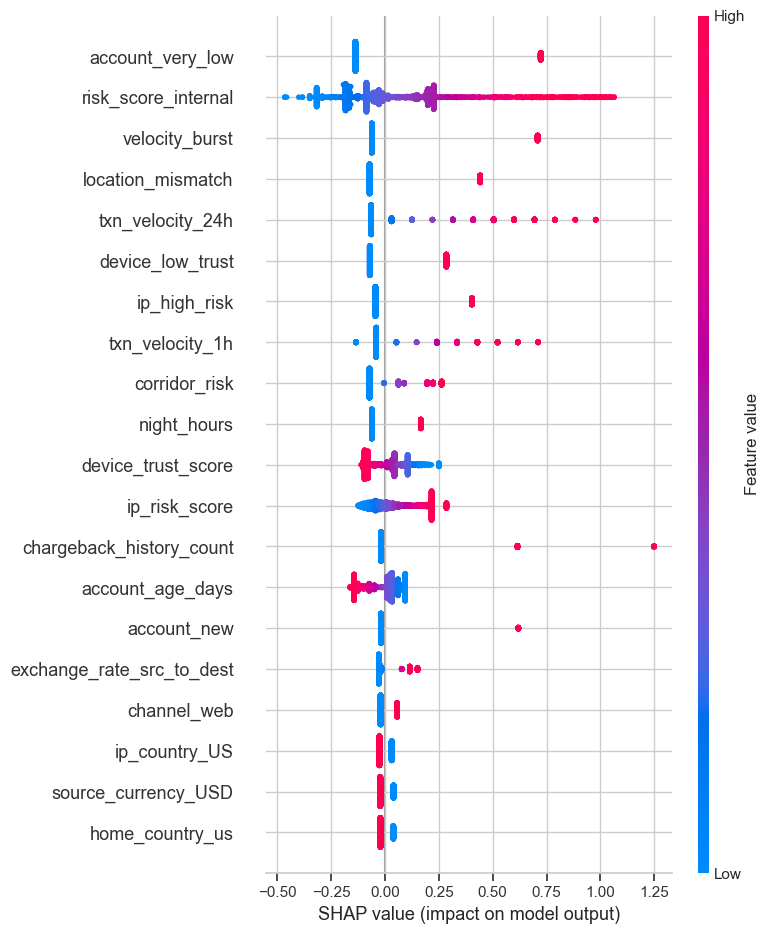

In [87]:
# Output Global importance plots ---
# Summary (beeswarm)
shap.summary_plot(shap_values, X_sample, feature_names=feature_names, show=False)
plt.tight_layout()
plt.show()

The SHAP values above show the features with both +ve and -ve values which impact performance of the model. The features in the top half have very significant impact while the features in the bottom half tend to have less significant impact on the model. 

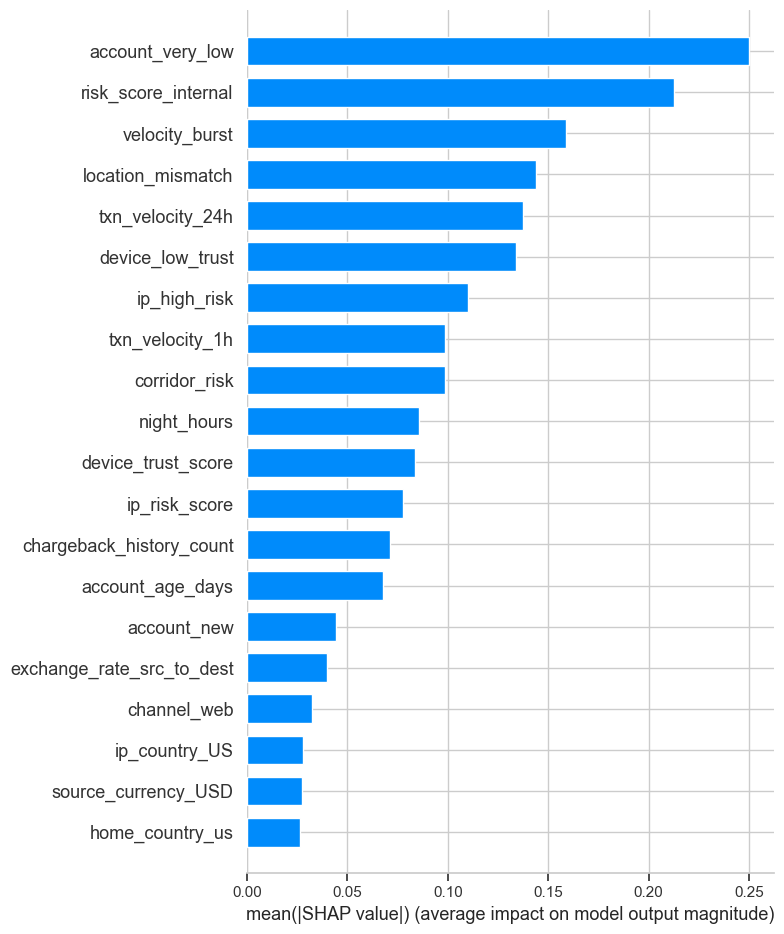

In [88]:
# Summary (bar)
shap.summary_plot(shap_values, X_sample, feature_names=feature_names, plot_type="bar", show=False)
plt.tight_layout()
plt.show()

The plot above is a replica of the one before which highlights the impact of each feature on the model with accoun_very_low being the most impactful and home_country_us being the least.

In [89]:
# Top features table (report-ready) ---
mean_abs = np.abs(shap_values).mean(axis=0)
top_feats = (pd.DataFrame({"feature": feature_names, "mean_abs_shap": mean_abs})
               .sort_values("mean_abs_shap", ascending=False)
               .head(25))

display(top_feats)

,feature,mean_abs_shap
21,account_very_low,0.249967
10,risk_score_internal,0.212650
23,velocity_burst,0.158709
5,location_mismatch,0.143950
12,txn_velocity_24h,0.137457
26,device_low_trust,0.133952
25,ip_high_risk,0.109956
11,txn_velocity_1h,0.098813
13,corridor_risk,0.098463
20,night_hours,0.085761


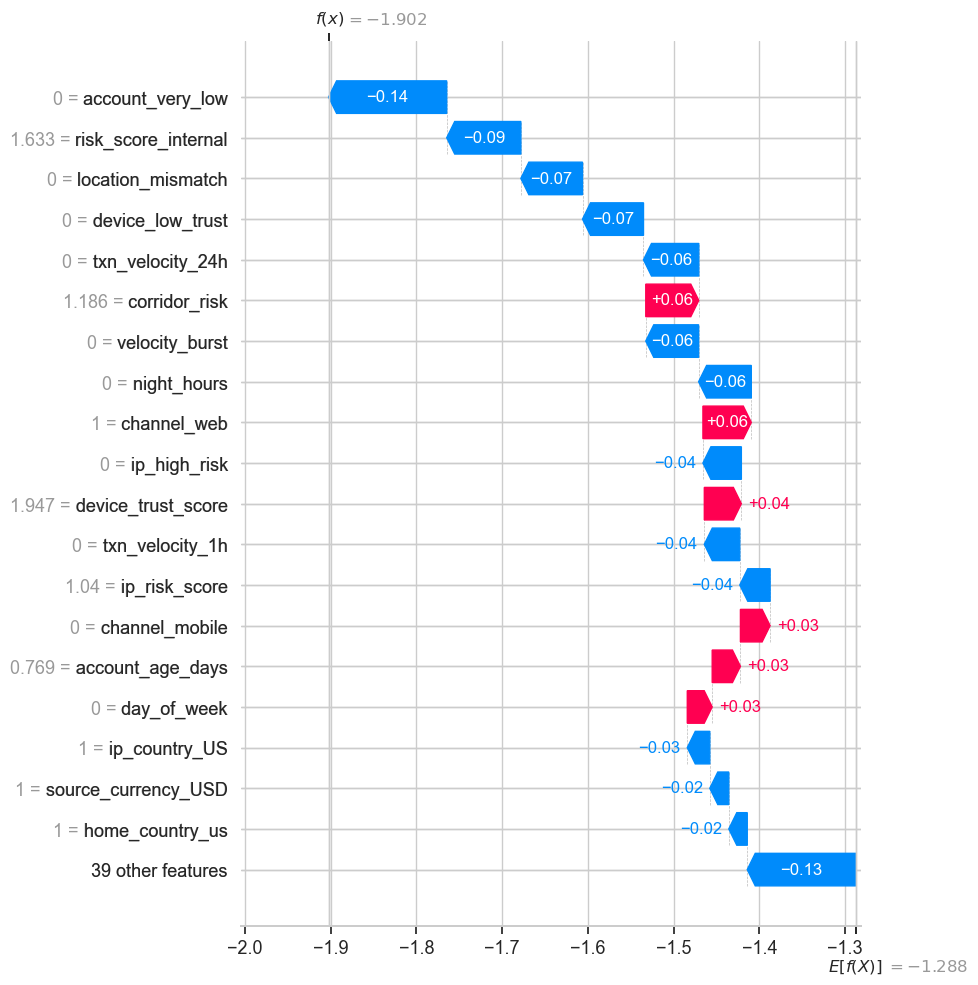

In [90]:
# Local explanation for ONE transaction (choosing a row from X_test) ---
row = 0  # change to any test row index you want (0..len(X_test)-1)
x1 = X_test.iloc[[row]]
x1_trans = to_dense(pre.transform(x1))

sv1 = explainer.shap_values(x1_trans)  # shape: (1, n_features)

# Waterfall plot (top contributors)
exp1 = shap.Explanation(
    values=sv1[0],
    base_values=base_value,
    data=x1_trans[0],
    feature_names=feature_names
)

shap.plots.waterfall(exp1, max_display=20)
plt.show()

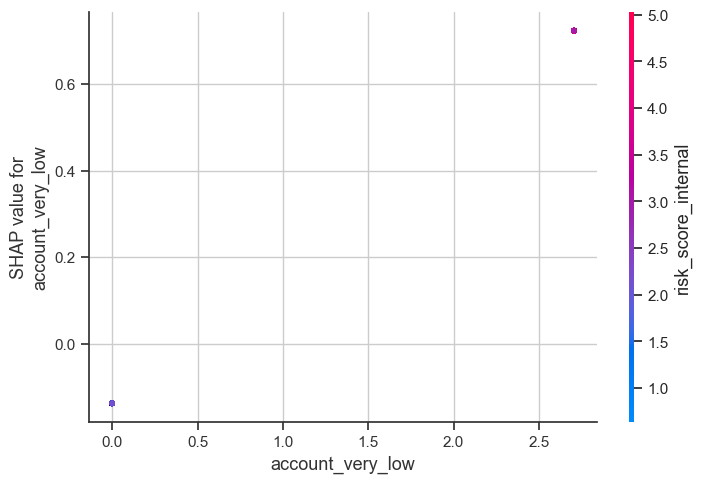

In [91]:
# Dependence plot for a specific feature ---
# Using a feature from top_feats["feature"] (note: with one-hot, names can look like "channel_card")
feat = top_feats.iloc[0]["feature"]
shap.dependence_plot(
    feat, shap_values, X_sample, feature_names=feature_names, show=False
)
plt.tight_layout()
plt.show()

In [92]:
# plotting the Top 10 SHAP drivers 
mean_abs = np.abs(shap_values).mean(axis=0)
mean_signed = shap_values.mean(axis=0)

drivers = (pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs,
    "mean_shap": mean_signed
})
.sort_values("mean_abs_shap", ascending=False))

drivers["direction"] = np.where(drivers["mean_shap"] >= 0, "↑ increases fraud risk", "↓ decreases fraud risk")

top10_drivers = drivers.head(10).reset_index(drop=True)
display(top10_drivers)

,feature,mean_abs_shap,mean_shap,direction
0,account_very_low,0.249967,0.027330,↑ increases fraud risk
1,risk_score_internal,0.212650,0.023193,↑ increases fraud risk
2,velocity_burst,0.158709,0.053955,↑ increases fraud risk
3,location_mismatch,0.143950,0.028202,↑ increases fraud risk
4,txn_velocity_24h,0.137457,0.042291,↑ increases fraud risk
5,device_low_trust,0.133952,0.033649,↑ increases fraud risk
6,ip_high_risk,0.109956,0.036638,↑ increases fraud risk
7,txn_velocity_1h,0.098813,0.026945,↑ increases fraud risk
8,corridor_risk,0.098463,-0.004987,↓ decreases fraud risk
9,night_hours,0.085761,-0.008520,↓ decreases fraud risk


In [93]:
# Preparing Auto-generate a narrative summary
def clean_feature_name(f):
    # Make one-hot names easier to read
    # Examples: "channel_card" -> "channel = card"
    if "_" in f and (f.split("_")[0] in ["home", "ip", "source", "dest", "channel", "kyc", "corridor"]):
        # only lightly transform, keep safe
        parts = f.split("_", 1)
        return f"{parts[0]} = {parts[1]}"
    # For OneHotEncoder default names, we might see "channel_card" already.
    # We'll just return as-is.
    return f

lines = []
for _, r in top10_drivers.iterrows():
    fname = clean_feature_name(r["feature"])
    direction = "increases" if r["mean_shap"] >= 0 else "reduces"
    lines.append(f"- **{fname}**: on average, this feature **{direction}** predicted fraud risk (mean |SHAP| = {r['mean_abs_shap']:.4f}).")

print("\n".join(lines))

- **account_very_low**: on average, this feature **increases** predicted fraud risk (mean |SHAP| = 0.2500).
- **risk_score_internal**: on average, this feature **increases** predicted fraud risk (mean |SHAP| = 0.2127).
- **velocity_burst**: on average, this feature **increases** predicted fraud risk (mean |SHAP| = 0.1587).
- **location_mismatch**: on average, this feature **increases** predicted fraud risk (mean |SHAP| = 0.1439).
- **txn_velocity_24h**: on average, this feature **increases** predicted fraud risk (mean |SHAP| = 0.1375).
- **device_low_trust**: on average, this feature **increases** predicted fraud risk (mean |SHAP| = 0.1340).
- **ip = high_risk**: on average, this feature **increases** predicted fraud risk (mean |SHAP| = 0.1100).
- **txn_velocity_1h**: on average, this feature **increases** predicted fraud risk (mean |SHAP| = 0.0988).
- **corridor = risk**: on average, this feature **reduces** predicted fraud risk (mean |SHAP| = 0.0985).
- **night_hours**: on average, t

In [94]:
# Building a function to export explanations for any set of rows
from sklearn.metrics import roc_auc_score, average_precision_score

def export_shap_explanations(
    best_pipe,
    explainer,
    X_raw,              # raw features dataframe (e.g., X_test)
    y_true=None,        # optional series
    out_csv="novapay_shap_explanations.csv",
    n_rows=200,         # how many rows to export
    top_k=8,            # top +/- features
    random_state=42
):
    pre = best_pipe.named_steps["preprocess"]
    feature_names = pre.get_feature_names_out()

    rng = np.random.RandomState(random_state)
    n_rows = min(n_rows, len(X_raw))
    idx = rng.choice(len(X_raw), size=n_rows, replace=False)

    X_sel_raw = X_raw.iloc[idx].copy()
    X_sel_trans = pre.transform(X_sel_raw)
    X_sel_dense = X_sel_trans.toarray() if hasattr(X_sel_trans, "toarray") else X_sel_trans

    # Model probabilities
    proba = best_pipe.predict_proba(X_sel_raw)[:, 1]

    # SHAP values
    sv = explainer.shap_values(X_sel_dense)  # (n_rows, n_features)
    base_value = explainer.expected_value

    rows = []
    for i in range(n_rows):
        contrib = sv[i]
        order_pos = np.argsort(contrib)[::-1]  # descending
        order_neg = np.argsort(contrib)        # ascending

        top_pos = [(feature_names[j], contrib[j]) for j in order_pos[:top_k]]
        top_neg = [(feature_names[j], contrib[j]) for j in order_neg[:top_k]]

        row = {
            "row_index": int(X_sel_raw.index[i]),
            "fraud_proba": float(proba[i]),
            "base_value": float(base_value),
        }
        if y_true is not None:
            row["is_fraud_true"] = int(y_true.loc[X_sel_raw.index[i]])

        # store as readable strings
        row["top_positive_drivers"] = "; ".join([f"{f}={v:+.4f}" for f, v in top_pos])
        row["top_negative_drivers"] = "; ".join([f"{f}={v:+.4f}" for f, v in top_neg])

        rows.append(row)

    out_df = pd.DataFrame(rows).sort_values("fraud_proba", ascending=False)
    out_df.to_csv(out_csv, index=False)
    print(f"Saved {len(out_df)} rows to {out_csv}")
    return out_df

In [95]:
# Run export on your test set (example: 500 rows)
explanations_df = export_shap_explanations(
    best_pipe=best_pipe,
    explainer=explainer,
    X_raw=X_test,
    y_true=y_test,
    out_csv="novapay_shap_explanations_test.csv",
    n_rows=500,
    top_k=8
)

display(explanations_df.head(10))


Saved 500 rows to novapay_shap_explanations_test.csv


,row_index,fraud_proba,base_value,is_fraud_true,top_positive_drivers,top_negative_drivers
182,9206,0.995875,-1.287622,1,chargeback_history_count=+1.2493; risk_score_i...,account_very_low=-0.1377; ip_country_US=-0.026...
10,10579,0.995355,-1.287622,1,risk_score_internal=+0.9945; txn_velocity_24h=...,channel_mobile=-0.0212; exchange_rate_src_to_d...
172,9595,0.994489,-1.287622,1,chargeback_history_count=+1.2493; risk_score_i...,corridor_risk=-0.0723; kyc_tier_enhanced=-0.06...
296,10933,0.992233,-1.287622,1,risk_score_internal=+0.8517; velocity_burst=+0...,account_very_low=-0.1377; corridor_risk=-0.072...
471,9205,0.992159,-1.287622,1,risk_score_internal=+1.0047; velocity_burst=+0...,account_very_low=-0.1377; source_currency_USD=...
85,9177,0.991865,-1.287622,1,chargeback_history_count=+1.2493; txn_velocity...,account_very_low=-0.1377; night_hours=-0.0614;...
344,10956,0.991652,-1.287622,1,risk_score_internal=+0.9146; account_very_low=...,corridor_risk=-0.0723; exchange_rate_src_to_de...
242,10665,0.991290,-1.287622,1,risk_score_internal=+0.8347; account_very_low=...,night_hours=-0.0614; channel_mobile=-0.0212; c...
147,10678,0.991073,-1.287622,1,chargeback_history_count=+1.2493; risk_score_i...,corridor_risk=-0.0723; night_hours=-0.0614; ip...
288,10024,0.990584,-1.287622,1,risk_score_internal=+0.9656; txn_velocity_24h=...,corridor_risk=-0.0723; exchange_rate_src_to_de...


# Findings Report Summary:

NovaPay Limited — Fraud Prediction Model Management Report

Subject: Outcomes of Supervised ML Fraud Model (Logistic Regression) + Explainability (SHAP) and Operational Recommendations

Report summary:

NovaPay’s supervised fraud prediction model has delivered high-confidence fraud detection performance on a held-out test set using a time-based (chronological) split. The best performing model (Logistic Regression) achieved zero false positives while identifying the majority of fraudulent transactions. This performance profile is operationally attractive because it minimizes customer friction and avoids unnecessary transaction declines, while still preventing a significant proportion of fraud losses.

SHAP explainability analysis shows that NovaPay’s fraud risk is driven primarily by account quality, velocity behaviour, device trust, IP risk, and location mismatch indicators consistent with common fraud attack patterns in digital payments. These insights provide a clear blueprint for operational improvements: risk-tiered decisioning, targeted step-up authentication, velocity controls, device and IP risk hardening, and policy tuning by risk segments.

1) Model performance summary (business interpretation)
Confusion matrix (test set)

True Negatives (TN): 1898 — legitimate transactions correctly approved

False Positives (FP): 0 — legitimate transactions incorrectly flagged (customer friction)

False Negatives (FN): 25 — fraud transactions missed (loss exposure)

True Positives (TP): 283 — fraud transactions correctly flagged (loss prevention)

What this means for NovaPay operations

Precision (Fraud alerts quality): 100% (283 / (283 + 0))
Every transaction flagged as fraud was actually fraud.
→ This is ideal for automated blocking and/or high-confidence review queues.

Recall (Fraud capture rate): ~91.9% (283 / (283 + 25))
NovaPay catches roughly 92% of fraud in the test period.
→ Strong prevention capability with limited residual risk.

Customer impact: 0 false positives
→ The model is exceptionally “customer-safe” in its current configuration.

Executive takeaway

This model can be used immediately to reduce fraud losses with minimal customer disruption, provided that deployment includes standard governance (monitoring, drift checks, periodic retraining) and validation that no “post-outcome” data leaks into features.

2) Explainability findings (SHAP) — “What drives fraud risk”
Top drivers increasing fraud risk (highest mean |SHAP|)

account_very_low (↑)

risk_score_internal (↑)

velocity_burst (↑)

location_mismatch (↑)

txn_velocity_24h (↑)

device_low_trust (↑)

ip_high_risk (↑)

txn_velocity_1h (↑)

Drivers reducing fraud risk (in this dataset/model)

corridor_risk (↓ slightly)

night_hours (↓ slightly)

Interpretation:

Fraud risk increases when accounts appear very weak/low quality, when internal risk scoring is high, when transaction patterns show burst behaviour, when the device is untrusted, when the IP is high risk, and when the IP location mismatches expected customer context.

Velocity features (1h and 24h) are especially important, fraud often shows rapid repeats and volume spikes.

Important note for management: If risk_score_internal is computed using post-investigation outcomes (e.g., chargeback-confirmed fraud), it may inflate model performance. Confirm it is available at decision time (pre-authorization) to ensure the results are production-valid.

3) Evidence from per-transaction explanations (operational traceability)

Your exported SHAP audit file (e.g., novapay_shap_explanations_test.csv) shows high-risk examples with fraud probabilities ~0.99. Top positive drivers repeatedly include:

risk_score_internal

chargeback_history_count

txn_velocity_24h / velocity_burst

location mismatch

low trust device

IP high risk

This provides NovaPay with an “explainable decision trail” suitable for:

fraud analyst investigations,

compliance/audit,

policy justification for step-up checks or blocking.

4) Recommended actions for NovaPay (what to do next)
   
A) Deploy as a tiered decision engine (best practice)

Do not use a simple “block/approve” only. Use risk tiers:

Recommended operating policy

Low risk: Auto-approve

Medium risk: Step-up verification (OTP/biometric/device confirmation)

High risk: Block or hold + route to fraud operations

Why this fits your results:

With 100% precision, NovaPay can confidently apply high-risk blocking/holds with minimal customer friction.

To reduce the remaining 25 missed frauds, NovaPay can widen the medium-risk step-up band to capture more fraud without creating broad false declines.

B) Strengthen velocity controls (high ROI)

Because velocity_burst, txn_velocity_1h, txn_velocity_24h are top drivers:

Introduce adaptive velocity limits (by KYC tier, account age, trust score)

Trigger step-up checks when burst behaviour begins (not after it escalates)

Apply “progressive friction”: first alert → OTP, repeated bursts → temporary hold

C) Improve device and IP trust posture

Given device_low_trust and ip_high_risk are strong drivers:

Device binding (trusted device program)

Risk-based device challenges (new_device + low_trust → step-up)

IP reputation integration + geo-anomaly policy (location mismatch → step-up)

D) Account quality interventions

Since account_very_low is the strongest driver:

Tighten onboarding for low-quality segments (higher KYC for higher amounts)

Limit transaction size/velocity for new and low-tier accounts until trust established

Add progressive limits that relax with good behaviour and tenure

E) Use explainability outputs to improve fraud operations

Provide analysts with the “Top drivers” field for each alert (already in your CSV)

Standardize playbooks:

“Velocity burst + IP high risk” → hold + verify recipient

“Location mismatch + new device” → step-up + device binding

“Chargeback history + high risk score” → block + investigate linked entities

5) Implementation roadmap (practical and executive-friendly)
Phase 1 — Controlled rollout (2–4 weeks)

Deploy in shadow mode (score transactions but don’t block)

Compare outcomes to existing rules and manual decisions

Validate that all features are available pre-decision (no leakage)

Define operating thresholds for high/medium/low bands

Success criteria: model stability + consistent explainability + no performance degradation

Phase 2 — Production decisioning (4–8 weeks)

Activate high-risk holds/blocks

Activate medium-risk step-up checks

Integrate analyst case management using SHAP driver summaries

Monitor KPIs daily/weekly

Phase 3 — Continuous improvement (ongoing)

Monthly/quarterly retraining (depending on fraud drift)

Drift monitoring on top SHAP features

Expand feature set to capture the 25 missed fraud cases (FN analysis)

6) KPIs and governance NovaPay should track

Executives should monitor these weekly:

Model performance KPIs

Fraud recall (catch rate)

False positive rate (customer friction)

PR-AUC (imbalanced performance)

Approval rate impact

Business KPIs

£ fraud prevented (estimated: TP × average loss per fraud)

Chargeback rate trend

Manual review volume and hit-rate

Customer complaints / friction metrics (OTP failure rate, drop-off)

Model risk governance

Data drift on: txn_velocity_*, device_trust_score, ip_risk_score, location_mismatch

Stability of top SHAP drivers over time

Audit log retention of per-transaction explanations

7) Key risks and how to mitigate

Feature leakage risk (e.g., risk_score_internal, chargeback_history_count)

Mitigation: confirm all features are generated before fraud outcome is known.

Fraud adaptation risk (attackers change behaviour)

Mitigation: drift monitoring + regular retraining + rule “guardrails”.

Over-reliance on a single model

Mitigation: hybrid approach (model + rules) and champion/challenger testing.

Conclusion: Executive decision

NovaPay should proceed with deployment of this model as a risk-tiered decisioning system, leveraging SHAP-based explainability for transparency, operational playbooks, and audit readiness. The combination of zero false positives and ~92% fraud capture indicates immediate business value: reduced losses, reduced analyst waste, and minimal customer disruption.

# Executive Management Report:

1. Executive Summary

NovaPay has developed and validated a supervised machine learning fraud detection model designed to identify fraudulent transactions in real time while minimizing customer disruption. The best performing model (Logistic Regression) achieved zero false positives and approximately 92% fraud detection recall on a chronological holdout test set.
This performance profile is operationally strong: fraudulent transactions are detected with high confidence, while legitimate customers experience no unnecessary transaction declines.

2. Model Performance Overview

Confusion Matrix (Out-of-Time Test Set):
True Negatives (TN): 1898
False Positives (FP): 0
False Negatives (FN): 25
True Positives (TP): 283
Key Performance Metrics:
• Precision (Fraud Alerts Quality): 100%
• Recall (Fraud Detection Rate): ~91.9%
• False Positive Rate: 0%
• Overall Accuracy: ~98.9%
Interpretation: The model prevents the vast majority of fraud while avoiding any false declines of legitimate transactions. This is ideal for customer trust and operational efficiency.

3. Explainability Insights (SHAP Analysis)

Top Drivers Increasing Fraud Risk:
• account_very_low
• risk_score_internal
• velocity_burst
• location_mismatch
• txn_velocity_24h
• device_low_trust
• ip_high_risk
• txn_velocity_1h
Drivers Reducing Fraud Risk:
• corridor_risk (slight reduction effect)
• night_hours (minor protective effect)
Fraud risk is strongly associated with weak account quality, burst transaction activity, untrusted devices, IP risk signals, and geographic anomalies. These insights are consistent with industry fraud patterns and validate NovaPay’s existing risk logic.

4. Operational Recommendations

A. Deploy Risk-Tiered Decisioning Framework
Implement three risk bands: Low (auto-approve), Medium (step-up verification), High (block or manual review).
B. Strengthen Velocity Controls
Introduce adaptive transaction limits and real-time alerts when velocity burst behavior is detected.
C. Enhance Device and IP Risk Management
Adopt device binding programs and location anomaly detection to reduce fraud exposure.
D. Improve Account Quality Governance
Apply graduated transaction limits based on account tenure, KYC tier, and trust profile.

5. Governance & Monitoring Framework

Recommended KPIs:
• Fraud Recall Rate
• False Positive Rate
• Chargeback Rate
• Fraud Loss Prevented (£)
• Data Drift Monitoring on Key Risk Drivers
Continuous monitoring, quarterly model retraining, and explainability audits are recommended to maintain effectiveness as fraud patterns evolve.

6. Implementation Roadmap

Phase 1: Shadow deployment and validation (2–4 weeks)
Phase 2: Controlled production rollout with risk-tier logic (4–8 weeks)
Phase 3: Continuous learning and drift monitoring (ongoing)

7. Executive Conclusion

The AI-driven fraud detection system positions NovaPay to significantly reduce fraud losses while maintaining exceptional customer experience. The model’s zero false positive rate and high recall performance provide immediate operational value. Deployment is recommended under a phased, monitored rollout strategy.